# ExLightNet: an honest CPU reproduction

Fast mode trains seed 42 for one epoch per final deep model and alpha candidate, with reduced SHAP. Full mode only loads cached results from the parallel pipeline (`python scripts/run_parallel.py`), including its final isolated benchmark pass. Paper results are quotations, never generated outputs.

## 0. Environment

Set RUN_MODE here; restart and run all. The first fast run performs live training; later runs reuse frozen evaluations.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src/exlightnet").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/exlightnet-mpl")
RUN_MODE = os.environ.get("EXLIGHTNET_RUN_MODE", "fast")
from IPython.display import display
import pandas as pd
from exlightnet.bench import environment_info
from exlightnet.io import read_json
from exlightnet.preprocess import FlowPreprocessor
from exlightnet import notebook as presentation
display(environment_info())
print("This notebook executes on the CPU. The displayed library versions and processor describe this environment.")

{'platform': 'Linux-6.1.0-32-amd64-x86_64-with-glibc2.36',
 'cpu': 'Intel(R) Core(TM) i5-8500 CPU @ 3.00GHz',
 'python': '3.11.2',
 'versions': {'numpy': '1.26.4',
  'pandas': '2.2.3',
  'scipy': '1.14.1',
  'torch': '2.6.0+cpu',
  'scikit-learn': '1.6.1',
  'xgboost-cpu': '2.1.4',
  'shap': '0.46.0',
  'nbformat': '5.10.4',
  'nbconvert': '7.16.6',
  'pytest': '8.3.5'},
 'cuda_used': False,
 'torch_threads': 1,
 'torch_interop_threads': 6,
 'threadpools': [{'api': 'blas', 'library': 'openblas', 'threads': 1},
  {'api': 'openmp', 'library': 'openmp', 'threads': 1},
  {'api': 'openmp', 'library': 'openmp', 'threads': 1},
  {'api': 'blas', 'library': 'openblas', 'threads': 1}]}

This notebook executes on the CPU. The displayed library versions and processor describe this environment.


## 1. Data and D1/D2

The genuine corpus is required in fast mode; no synthetic replacement is used.

In [2]:
if RUN_MODE == "fast":
    from exlightnet.run_all import prepare_data
    _, _, _, data_context = prepare_data(ROOT)
gates = read_json(ROOT / "results/data_gates.json")
display(pd.DataFrame(gates))
print("D1/D2 status comes from the actual row counts, split sizes and class supports shown above. A failed hard gate stops dependent training.")

,gate,pass,actual
0,D1,True,"{'rows': 123117, 'counts': {'mqtt_publish': 41..."
1,D2,True,"{'sizes': {'train': 86181, 'val': 18468, 'test..."


D1/D2 status comes from the actual row counts, split sizes and class supports shown above. A failed hard gate stops dependent training.


## 2. Train-only preprocessing and MI

Feature identity follows computed descending MI order, with the vocabulary and all statistics frozen from train.

In [3]:
pp = FlowPreprocessor.load(ROOT / "artifacts")
display(pp.compare_table4())
display(pd.DataFrame(pp.ranking_[:40]))
print(f"The computed selection shares {pp.compare_table4()['overlap_count']} of 40 paper features. The displayed rank correlation measures ordering agreement and was not forced.")

{'gate': 'P1',
 'report_only': True,
 'overlap_count': 40,
 'budget': 40,
 'spearman_shared_ranks': 0.9994371482176362,
 'shared_features': ['fwd_pkts_payload.avg',
  'fwd_pkts_payload.max',
  'fwd_subflow_bytes',
  'flow_pkts_payload.tot',
  'flow_pkts_payload.std',
  'fwd_pkts_payload.tot',
  'flow_pkts_payload.avg',
  'flow_pkts_payload.max',
  'flow_iat.min',
  'bwd_subflow_bytes',
  'bwd_pkts_payload.tot',
  'bwd_pkts_payload.avg',
  'bwd_pkts_payload.max',
  'flow_iat.tot',
  'flow_iat.max',
  'flow_duration',
  'active.max',
  'active.tot',
  'active.avg',
  'fwd_iat.min',
  'payload_bytes_per_second',
  'active.min',
  'fwd_pkts_per_sec',
  'flow_pkts_per_sec',
  'fwd_iat.max',
  'bwd_pkts_per_sec',
  'fwd_iat.tot',
  'bwd_pkts_payload.std',
  'flow_iat.avg',
  'fwd_iat.avg',
  'bwd_iat.tot',
  'bwd_iat.max',
  'fwd_header_size_tot',
  'bwd_header_size_tot',
  'bwd_iat.avg',
  'flow_iat.std',
  'id.resp_p',
  'bwd_header_size_max',
  'bwd_header_size_min',
  'bwd_data_pkts_tot'

,rank,feature,mi
0,1,fwd_pkts_payload.avg,0.318111
1,2,fwd_pkts_payload.max,0.311076
2,3,fwd_subflow_bytes,0.310022
3,4,flow_pkts_payload.tot,0.307841
4,5,flow_pkts_payload.std,0.305293
5,6,fwd_pkts_payload.tot,0.305003
6,7,flow_pkts_payload.avg,0.301783
7,8,flow_pkts_payload.max,0.300659
8,9,flow_iat.min,0.298581
9,10,bwd_subflow_bytes,0.296417


The computed selection shares 40 of 40 paper features. The displayed rank correlation measures ordering agreement and was not forced.


## 3. Architecture and M1

Conv lengths are 40 → 38 → 36 → 34; convolutions have no padding or biases.

In [4]:
from exlightnet.model import ExLightNet, model_gate
display(ExLightNet(12))
display(model_gate())
print("M1 checks the runtime parameter counts for both heads and the no-SE variant. The per-stage counts come from the constructed graph.")

ExLightNet(
  (stem): Sequential(
    (0): Conv1d(1, 48, kernel_size=(3,), stride=(1,), bias=False)
    (1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
  )
  (block1): Block(
    (conv): Sequential(
      (0): Conv1d(48, 48, kernel_size=(3,), stride=(1,), groups=48, bias=False)
      (1): Conv1d(48, 96, kernel_size=(1,), stride=(1,), bias=False)
    )
    (bn): BatchNorm1d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU()
    (se): SE(
      (pool): AdaptiveAvgPool1d(output_size=1)
      (fc1): Linear(in_features=96, out_features=24, bias=True)
      (relu): ReLU()
      (fc2): Linear(in_features=24, out_features=96, bias=True)
      (sigmoid): Sigmoid()
    )
  )
  (block2): Block(
    (conv): Sequential(
      (0): Conv1d(96, 96, kernel_size=(3,), stride=(1,), groups=96, bias=False)
      (1): Conv1d(96, 144, kernel_size=(1,), stride=(1,), bias=False)
    )
    (bn): BatchNorm1d(144, eps=1e-05, 

{'gate': 'M1',
 'pass': True,
 'actual': {'multiclass': 38328, 'binary': 35438, 'no_se': 23052},
 'stages': {'stem': 240, 'block1': 9672, 'block2': 24948, 'head': 3468}}

M1 checks the runtime parameter counts for both heads and the no-SE variant. The per-stage counts come from the constructed graph.


## 4. Live training in fast mode

Alpha selection and early stopping use validation only. Full mode does not train in this notebook.

In [5]:
manifest = presentation.experiment(ROOT, RUN_MODE)
display(manifest)
display(read_json(ROOT / "results" / RUN_MODE / "alpha_selection.json"))
print("The recorded seed list and epoch limits define the scope of these results. No best seed or test-selected epoch is reported.")

{'mode': 'full',
 'seeds': [42, 43, 44, 45, 46],
 'tasks': ['binary', 'multiclass'],
 'models': ['exlightnet',
  'mlp',
  'bilstm',
  'std_cnn',
  'random_forest',
  'xgboost'],
 'fast_max_epochs': None,
 'full_five_seed_headlines_complete': True,
 'elapsed_seconds_this_invocation': 2.668104565000249,
 'failures': [],
 'optional_kd': 'not implemented (lowest priority)',
 'leakage_proxy_requested': False,
 'stage': 'aggregate_only',
 'skip_benchmark': True,
 'pid': 1010041,
 'threads': 1,
 'started_at': '2026-11-16T15:11:13.102049+00:00',
 'finished_at': '2026-11-16T15:11:15.770158+00:00',
 'source_sha256': {'preprocess.py': 'c58cbd024bca1023f104bd3a9c5ccf8979a007af262ffec808f5b3f8265d0529',
  'losses.py': 'f45d93b98bbcc210dc1ec09c264d2c06581339411ee826f0866e4b2f515f7f77',
  'quantize.py': '65042ec46b68eeb8db3ddfb38c9b08c60c288bddebf8407f0cded3cd74a4ee2b',
  'run_all.py': '5e4f831400b6e6f1b648d1d82087aff80d8dcc06d151da37664dfb5c988443de',
  '__init__.py': 'e655fc81d4f9247f9c1bb6dc2467b1

{'binary': {'chosen': 'effective_num',
  'selection_metric': 'seed42 validation macro-F1',
  'seed': 42,
  'candidates': [{'mode': 'inv_freq',
    'validation_macro_f1': 0.9421064972406856,
    'best_epoch': 7},
   {'mode': 'sqrt_inv_freq',
    'validation_macro_f1': 0.9803234429850337,
    'best_epoch': 7},
   {'mode': 'effective_num',
    'validation_macro_f1': 0.9854911138018254,
    'best_epoch': 7},
   {'mode': 'none',
    'validation_macro_f1': 0.984458429601228,
    'best_epoch': 7}],
  'sweep_max_epochs': 8,
  'tie_break': 'first in inv_freq,sqrt_inv_freq,effective_num,none',
  'test_used': False,
  'data_fingerprint': 'dfba90bd116f9288bc72a837160516984ba773b11904e98561c80cda7dedcf5c'},
 'multiclass': {'chosen': 'none',
  'selection_metric': 'seed42 validation macro-F1',
  'seed': 42,
  'candidates': [{'mode': 'inv_freq',
    'validation_macro_f1': 0.6626591114313519,
    'best_epoch': 8},
   {'mode': 'sqrt_inv_freq',
    'validation_macro_f1': 0.7718128568257825,
    'best_epo

The recorded seed list and epoch limits define the scope of these results. No best seed or test-selected epoch is reported.


## 5. Binary results

Attack is class 1; decisions use two-logit argmax at a fixed threshold.

,model,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_seed42,accuracy_mean,macro_recall_mean,auc_mean
0,exlightnet,5,0.987069,0.00085,0.988054,0.995289,0.986079,0.997704


Per-class table and operating point below use seed 42.


,precision,recall,f1,support
normal,0.985931,0.971215,0.978518,1876.0
attack,0.996751,0.998433,0.997591,16592.0


,attack_recall,miss_count,fp_count,fpr,threshold
0,0.998433,26,54,0.028785,0.5


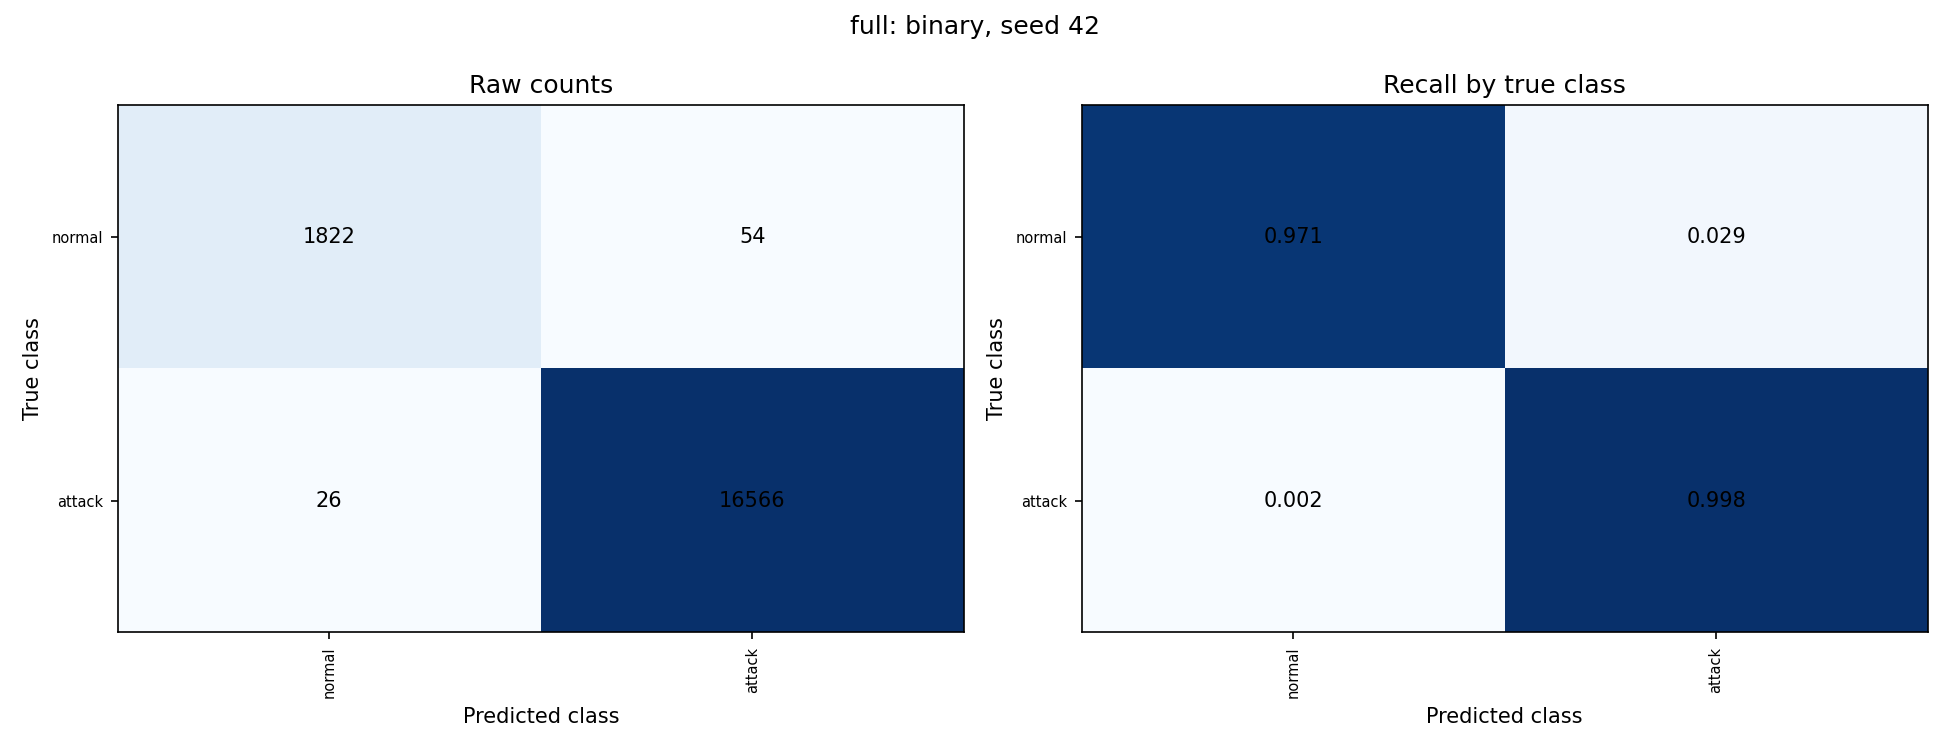

Across 5 seed(s), mean macro-F1 is 0.987069; seed 42 is 0.988054. Sample SD is 0.000850.


In [6]:
presentation.show_task(ROOT, RUN_MODE, "binary")

## 6. Twelve-class results

Per-class supports and row-normalised confusion expose failures hidden by accuracy.

,model,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_seed42,accuracy_mean,macro_recall_mean,auc_mean
0,exlightnet,5,0.846598,0.019463,0.824796,0.976825,0.869875,0.999718


Per-class table and operating point below use seed 42.


,precision,recall,f1,support
arp_poisioning,0.933946,0.961274,0.947413,1162.0
ddos_slowloris,0.784314,1.000000,0.879121,80.0
dos_syn_hping,1.000000,1.000000,1.000000,14199.0
metasploit_brute_force_ssh,0.833333,1.000000,0.909091,5.0
mqtt_publish,1.000000,0.995177,0.997583,622.0
nmap_fin_scan,0.375000,0.750000,0.500000,4.0
nmap_os_detection,0.566406,0.483333,0.521583,300.0
nmap_tcp_scan,0.986928,1.000000,0.993421,151.0
nmap_udp_scan,0.997151,0.899743,0.945946,389.0
nmap_xmas_tree_scan,0.545455,0.615894,0.578538,302.0


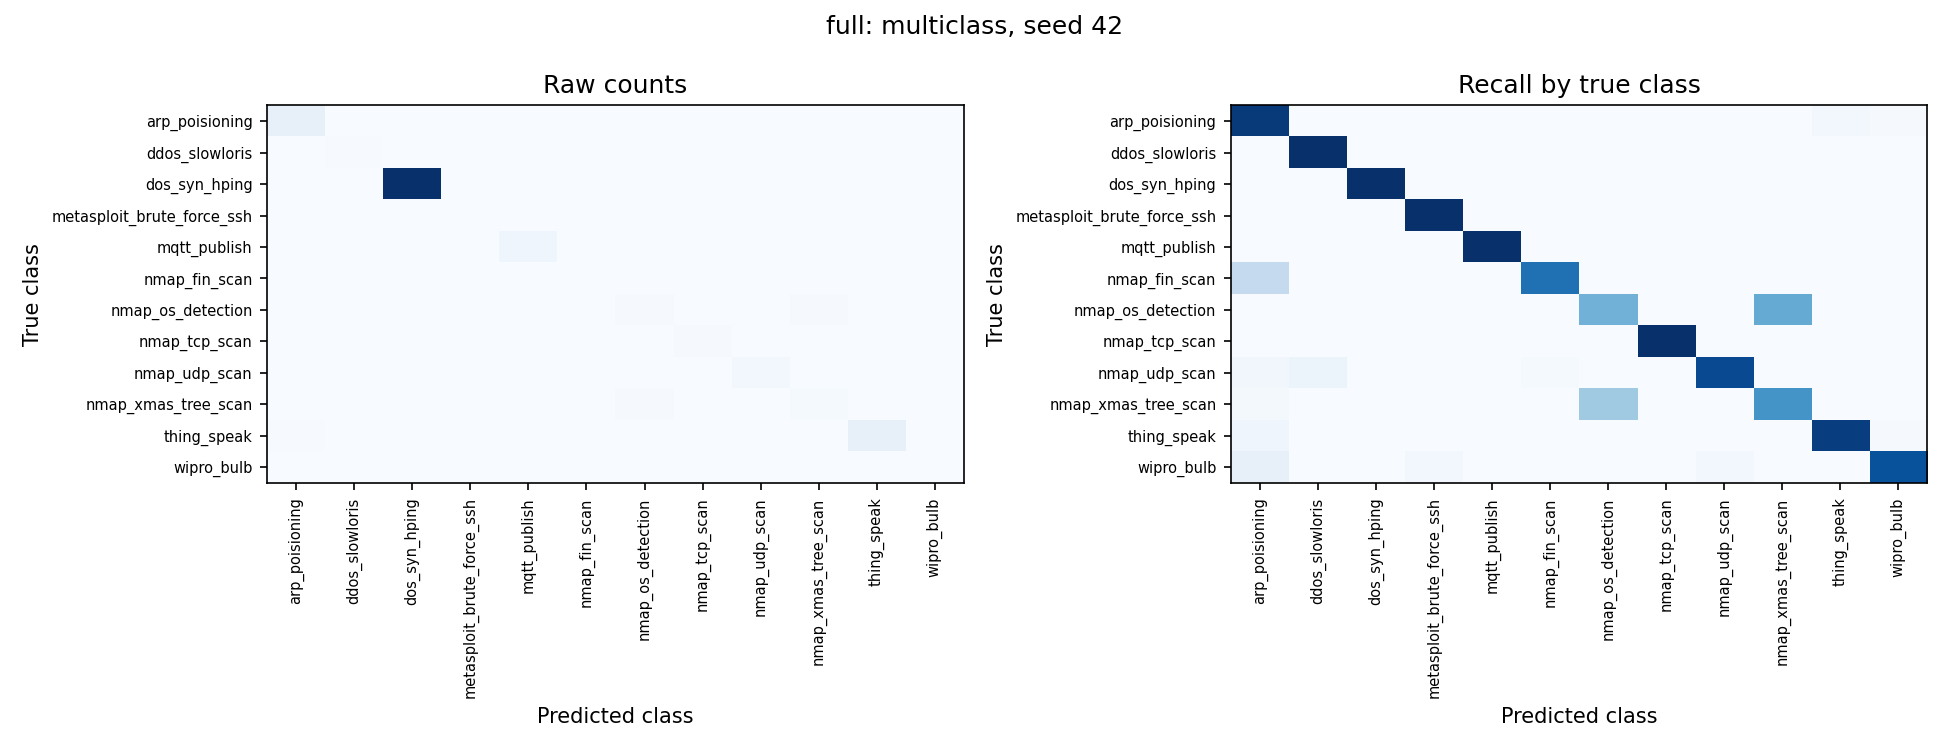

Across 5 seed(s), mean macro-F1 is 0.846598; seed 42 is 0.824796. Sample SD is 0.019463.


In [7]:
presentation.show_task(ROOT, RUN_MODE, "multiclass")

## 7. Baselines and seed variation

All headline models share the fixed partition and features; full mode uses five seeds.

In [8]:
presentation.show_baselines(ROOT, RUN_MODE)

,task,model,n_seeds,macro_f1_mean,macro_f1_std,macro_f1_seed42,five_seed_complete
0,binary,bilstm,5,0.963204,0.008207,0.961016,True
1,binary,exlightnet,5,0.987069,0.00085,0.988054,True
2,binary,mlp,5,0.9869,0.000596,0.987123,True
3,binary,random_forest,5,0.993733,0.000168,0.993791,True
4,binary,std_cnn,5,0.979657,0.005668,0.977757,True
5,binary,xgboost,5,0.993371,0.0,0.993371,True
6,multiclass,bilstm,5,0.72821,0.028676,0.770176,True
7,multiclass,exlightnet,5,0.846598,0.019463,0.824796,True
8,multiclass,mlp,5,0.835599,0.010353,0.835454,True
9,multiclass,random_forest,5,0.8596,0.002888,0.859192,True


Each model uses the same split and train-fitted forty features. Mean/sample-SD and seed-42 values use all completed runs; missing runs are flagged.


## 8. Ablations

The full model is reused as the reference rather than retrained for a second test pass.

In [9]:
presentation.show_ablations(ROOT, RUN_MODE)

,variant,paired_seeds,delta_macro_f1,paired_delta_std,full_seed_std,exceeds_full_seed_std,exceeds_paired_seed_std,interpretation
0,balanced,"[42, 43, 44, 45, 46]",-0.040086,0.039720,0.019463,True,True,"comparison with seed SD, not a significance test"
1,no_sampler,"[42, 43, 44, 45, 46]",-0.001958,0.053311,0.019463,False,False,"comparison with seed SD, not a significance test"
2,no_se,"[42, 43, 44, 45, 46]",-0.019584,0.033123,0.019463,True,False,"comparison with seed SD, not a significance test"
3,standard_conv,"[42, 43, 44, 45, 46]",0.015281,0.013250,0.019463,False,True,"comparison with seed SD, not a significance test"
4,top20,"[42, 43, 44, 45, 46]",-0.268743,0.019631,0.019463,True,True,"comparison with seed SD, not a significance test"


Deltas are variant minus full-model macro-F1 on paired seeds. The SD comparisons describe training variation and are not significance tests.


## 9. Weight-only quantisation

Per-channel INT8 storage is evaluated using dequantised floating-point weights.

In [10]:
presentation.show_quantization(ROOT, RUN_MODE)

,task,seed,pass,fp32_macro_f1,w8_macro_f1,delta,fp32_bytes,max_abs_weight_error,int8_bytes,quantized_weight_tensors,compute,size_breakdown
0,binary,42,True,0.988054,0.987762,-0.000293,152312,0.002242,48877,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
1,binary,43,True,0.987262,0.987552,0.000290,152312,0.002090,49694,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
2,binary,44,True,0.985706,0.985415,-0.000291,152312,0.002098,50446,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
3,binary,45,True,0.987098,0.987111,0.000012,152312,0.002102,49403,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
4,binary,46,True,0.987226,0.987371,0.000146,152312,0.002319,49892,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 34560, 'scales_fp3..."
5,multiclass,42,True,0.824796,0.825307,0.000511,163832,0.002410,55271,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."
6,multiclass,43,True,0.855791,0.851614,-0.004177,163832,0.002304,53843,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."
7,multiclass,44,True,0.873419,0.869331,-0.004088,163832,0.002149,52876,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."
8,multiclass,45,True,0.831274,0.837595,0.006321,163832,0.002302,53206,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."
9,multiclass,46,True,0.847711,0.850102,0.002391,163832,0.002550,53706,10,FP32 with dequantized W8 weights,"{'weights_only_int8_bytes': 37440, 'scales_fp3..."


Artifact sizes and metric changes are measured. Weight-only quantisation retains floating-point compute and does not establish an INT8 compute speedup.


## 10. Measured latency

Full-mode latency comes from the final benchmark-only pass: one process, one thread, batch one, with CPU-idle evidence recorded before each model.

In [11]:
presentation.show_latency(ROOT, RUN_MODE)

,task,model,seed,params,serialized_bytes,latency_mean_ms,latency_median_ms,latency_p95_ms,peak_rss_bytes
0,binary,exlightnet,42,35438.0,152312,0.617452,0.611172,0.652839,356163584
1,binary,exlightnet,43,35438.0,152312,0.621183,0.610853,0.660367,358146048
2,binary,exlightnet,44,35438.0,152312,0.605431,0.603468,0.621167,358146048
3,binary,exlightnet,45,35438.0,152312,0.605364,0.602642,0.631744,358146048
4,binary,exlightnet,46,35438.0,152312,0.603331,0.603034,0.630098,358146048
...,...,...,...,...,...,...,...,...,...
90,multiclass,exlightnet_w8,42,38328.0,55271,0.593708,0.592135,0.630522,616890368
91,multiclass,exlightnet_w8,43,38328.0,53843,0.592138,0.591728,0.612191,616890368
92,multiclass,exlightnet_w8,44,38328.0,52876,0.599908,0.590700,0.644268,616890368
93,multiclass,exlightnet_w8,45,38328.0,53206,0.592982,0.591298,0.622789,616890368


Measurements use one thread and batch one after 100 warmups, with 1000 timed inferences. Peak RSS is the whole process peak; no Raspberry Pi or multi-core throughput is inferred.


## 11. SHAP and faithfulness

The primary attribution target is the FP32 model's logits; deletion measures predicted-class probabilities.

,method,fallback_reason,additivity_max_abs,additivity_mean_abs
0,GradientExplainer,AssertionError: The SHAP explanations do not s...,2.1547,0.221882


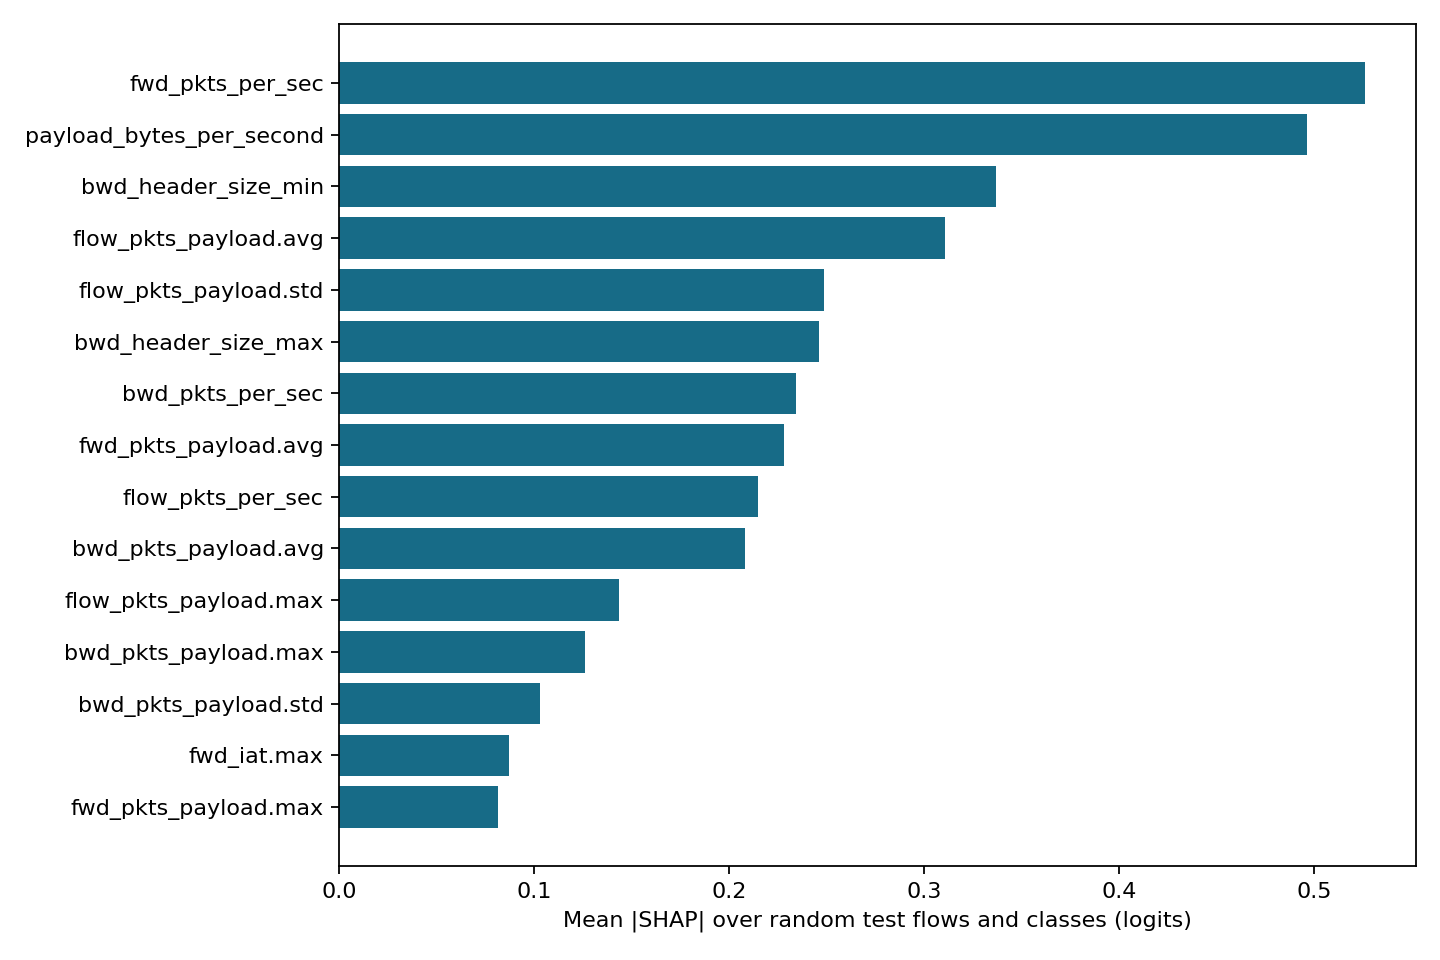

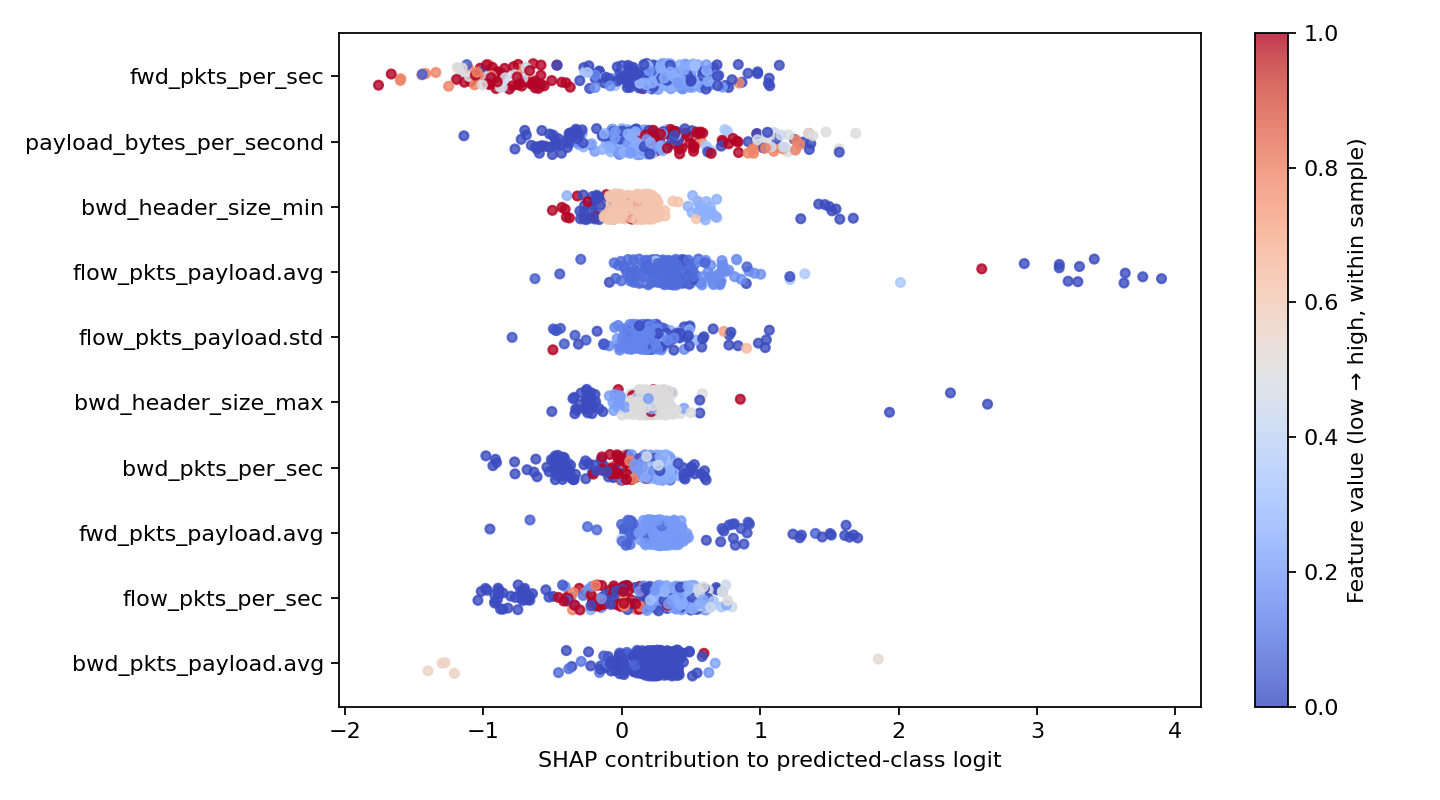

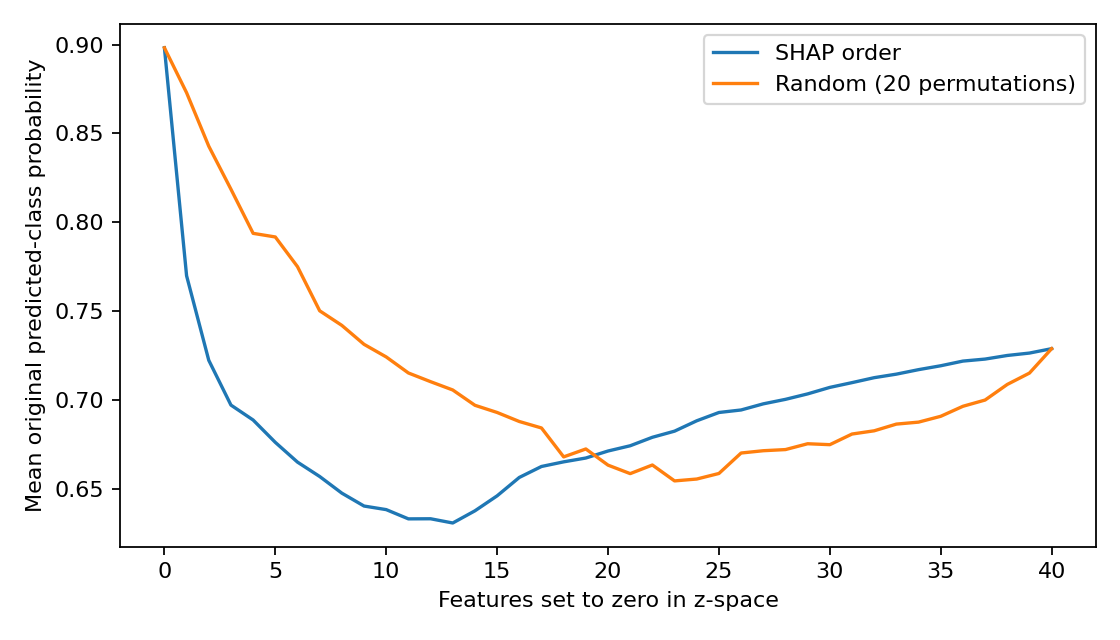

,spearman_top15_fp32_feature_set,top5_overlap
0,1.0,5


,true_class,predicted_class,correct,test_position,probability,top5
0,dos_syn_hping,dos_syn_hping,True,0,0.944329,"[{'feature': 'fwd_pkts_per_sec', 'signed_logit..."
1,nmap_os_detection,nmap_xmas_tree_scan,False,44,0.357215,"[{'feature': 'flow_pkts_payload.avg', 'signed_..."


SHAP explains FP32 logits using 200 train backgrounds and 300 random test flows. Deletion-AUC is 0.687726, versus 0.711405 for random ordering; lower means less retained original-class probability under this masking protocol.
DeepExplainer failed its additivity check. The fallback's displayed residuals limit additive-efficiency claims; these attributions are approximate diagnostics.


In [12]:
presentation.show_shap(ROOT, RUN_MODE)

## 12. Ours versus paper (quoted)

Reference values come only from PAPER_REPORTED; one-seed paper headlines are not multi-seed targets.

In [13]:
presentation.show_comparison(ROOT, RUN_MODE)

,task,model,n_seeds,ours_mean_macro_f1,ours_sample_std,ours_seed42_macro_f1,paper_quoted_macro_f1
0,binary,bilstm,5,0.963204,0.008207,0.961016,0.9354
1,binary,exlightnet,5,0.987069,0.000850,0.988054,0.9860
2,binary,exlightnet_w8,5,0.987042,0.000940,0.987762,0.9860
3,binary,mlp,5,0.986900,0.000596,0.987123,0.9800
4,binary,random_forest,5,0.993733,0.000168,0.993791,0.9934
5,binary,std_cnn,5,0.979657,0.005668,0.977757,0.9820
6,binary,xgboost,5,0.993371,0.000000,0.993371,0.9957
7,multiclass,balanced,5,0.806513,0.030542,0.829804,0.7807
8,multiclass,bilstm,5,0.728210,0.028676,0.770176,0.6380
9,multiclass,exlightnet,5,0.846598,0.019463,0.824796,0.8621


Paper columns are labelled quotations from PAPER_REPORTED. Agreement with a paper number is not a training objective, and fast mode does not estimate full-recipe performance.


## 13. Deviations and limitations

REPORT.md contains exact assumptions, gate evidence, hardware, runtime and stopped branches.

In [14]:
display(pd.DataFrame(read_json(ROOT / "results" / RUN_MODE / "failures.json")))
print("Fast mode cannot establish five-seed means and standard deviations; full-mode results remain separate. The random flow split may share attack-run artifacts across partitions, and four/five-flow rare-class supports limit inference.")
print("Baseline LSTM depth and CNN pooling are declared implementation choices. No Pi measurement, true INT8 arithmetic or campaign-disjoint generalisation is claimed.")

""


Fast mode cannot establish five-seed means and standard deviations; full-mode results remain separate. The random flow split may share attack-run artifacts across partitions, and four/five-flow rare-class supports limit inference.
Baseline LSTM depth and CNN pooling are declared implementation choices. No Pi measurement, true INT8 arithmetic or campaign-disjoint generalisation is claimed.
